In [ ]:
   from google.colab import drive
   drive.mount('/content/drive')
   !ls -lh /content/drive/MyDrive/CitizenTech

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
ls: cannot access '/content/drive/MyDrive/CitizenTech': No such file or directory


In [ ]:
import os, glob, zipfile, shutil, subprocess
from PIL import Image

candidatos = glob.glob('/content/drive/MyDrive/**/5y9wdsg2zt*.zip', recursive=True) + glob.glob('/content/5y9wdsg2zt*.zip')
print('Zips encontrados:', candidatos)
ZIP = candidatos[0]
print(f'Usando: {ZIP} | {os.path.getsize(ZIP)/1e6:.0f} MB')
print('Integridade (None = ok):', zipfile.ZipFile(ZIP).testzip())

shutil.rmtree('/content/data', ignore_errors=True)
os.makedirs('/content/data')
zipfile.ZipFile(ZIP).extractall('/content/data')
print(os.listdir('/content/data'))

Zips encontrados: ['/content/5y9wdsg2zt-1.zip']
Usando: /content/5y9wdsg2zt-1.zip | 241 MB
Integridade (None = ok): None
['Concrete Crack Images for Classification.rar']


In [ ]:
import subprocess

RAR = '/content/data/Concrete Crack Images for Classification.rar'
print(subprocess.run('apt-get -qq update && apt-get -qq install -y p7zip-full', shell=True, capture_output=True, text=True).stdout[-300:])

os.makedirs('/content/data/imagens', exist_ok=True)
r = subprocess.run(['7z', 'x', '-y', RAR, '-o/content/data/imagens'], capture_output=True, text=True)
print(r.stdout[-600:])
print(r.stderr[-600:])



7-Zip 23.01 (x64) : Copyright (c) 1999-2023 Igor Pavlov : 2023-06-20
 64-bit locale=en_US.UTF-8 Threads:2 OPEN_MAX:1048576

Scanning the drive for archives:
1 file, 241363336 bytes (231 MiB)

Extracting archive: /content/data/Concrete Crack Images for Classification.rar
--
Path = /content/data/Concrete Crack Images for Classification.rar
Type = Rar
Physical Size = 241363336
Solid = -
Blocks = 40002
Multivolume = -
Volumes = 1


Sub items Errors: 40000

Archives with Errors: 1

Sub items Errors: 40000

pported Method : Negative/19988.jpg
ERROR: Unsupported Method : Negative/19989.jpg
ERROR: Unsupported Method : Negative/19990.jpg
ERROR: Unsupported Method : Negative/19991.jpg
ERROR: Unsupported Method : Negative/19992.jpg
ERROR: Unsupported Method : Negative/19993.jpg
ERROR: Unsupported Method : Negative/19994.jpg
ERROR: Unsupported Method : Negative/19995.jpg
ERROR: Unsupported Method : Negative/19996.jpg
ERROR: Unsupported Method : Negative/19997.jpg
ERROR: Unsupported Method : Nega

In [ ]:
BASE = None
for raiz, pastas, _ in os.walk('/content/data/imagens'):
    nomes = {p.lower(): p for p in pastas}
    if 'negative' in nomes and 'positive' in nomes:
        BASE, NEG, POS = raiz, nomes['negative'], nomes['positive']
        break

print('BASE =', BASE)
print(len(os.listdir(f'{BASE}/{NEG}')), 'sem fissura |', len(os.listdir(f'{BASE}/{POS}')), 'com fissura')

for f in sorted(os.listdir(f'{BASE}/{NEG}'))[:5]:
    p = f'{BASE}/{NEG}/{f}'
    print(f, os.path.getsize(p), 'bytes |', subprocess.run(['file', '-b', p], capture_output=True, text=True).stdout.strip())
    try:
        print('  abre ok:', Image.open(p).size)
    except Exception as e:
        print('  FALHOU:', e)

BASE = /content/data/imagens
20000 sem fissura | 20000 com fissura
00001.jpg 0 bytes | empty
  FALHOU: cannot identify image file '/content/data/imagens/Negative/00001.jpg'
00002.jpg 0 bytes | empty
  FALHOU: cannot identify image file '/content/data/imagens/Negative/00002.jpg'
00003.jpg 0 bytes | empty
  FALHOU: cannot identify image file '/content/data/imagens/Negative/00003.jpg'
00004.jpg 0 bytes | empty
  FALHOU: cannot identify image file '/content/data/imagens/Negative/00004.jpg'
00005.jpg 0 bytes | empty
  FALHOU: cannot identify image file '/content/data/imagens/Negative/00005.jpg'


In [ ]:
import shutil, os
shutil.rmtree('/content/data/imagens', ignore_errors=True)
os.makedirs('/content/data/imagens')

In [ ]:
import subprocess

RAR = '/content/data/Concrete Crack Images for Classification.rar'
OUT = '/content/data/imagens'

def sh(cmd):
    return subprocess.run(cmd, shell=True, capture_output=True, text=True)

def deu_certo():
    for raiz, _, arqs in os.walk(OUT):
        for a in arqs:
            if a.lower().endswith('.jpg'):
                return os.path.getsize(f'{raiz}/{a}') > 0
    return False

tentativas = [
    ('unar',   'apt-get -qq install -y unar',          f'unar -q -f -o "{OUT}" "{RAR}"'),
    ('bsdtar', 'apt-get -qq install -y libarchive-tools', f'bsdtar -xf "{RAR}" -C "{OUT}"'),
    ('unrar',  'apt-get -qq install -y unrar',          f'unrar x -y "{RAR}" "{OUT}/"'),
]

for nome, instalar, extrair in tentativas:
    print(f'--- Tentando {nome} ---')
    sh('apt-get -qq update')
    print(sh(instalar).stderr[-200:])
    r = sh(extrair)
    print(r.stdout[-300:], r.stderr[-300:])
    if deu_certo():
        print(f'>>> Funcionou com {nome}')
        break
    print(f'{nome} não funcionou, limpando...')
    shutil.rmtree(OUT, ignore_errors=True); os.makedirs(OUT)

--- Tentando unar ---

 
>>> Funcionou com unar


In [ ]:
BASE = None
for raiz, pastas, _ in os.walk('/content/data/imagens'):
    nomes = {p.lower(): p for p in pastas}
    if 'negative' in nomes and 'positive' in nomes:
        BASE, NEG, POS = raiz, nomes['negative'], nomes['positive']
        break

print('BASE =', BASE)
print(len(os.listdir(f'{BASE}/{NEG}')), 'sem fissura |', len(os.listdir(f'{BASE}/{POS}')), 'com fissura')

for f in sorted(os.listdir(f'{BASE}/{NEG}'))[:5]:
    p = f'{BASE}/{NEG}/{f}'
    print(f, os.path.getsize(p), 'bytes |', subprocess.run(['file', '-b', p], capture_output=True, text=True).stdout.strip())
    try:
        print('  abre ok:', Image.open(p).size)
    except Exception as e:
        print('  FALHOU:', e)

BASE = /content/data/imagens/Concrete Crack Images for Classification
20000 sem fissura | 20000 com fissura
00001.jpg 5725 bytes | JPEG image data, JFIF standard 1.01, aspect ratio, density 1x1, segment length 16, baseline, precision 8, 227x227, components 3
  abre ok: (227, 227)
00002.jpg 4456 bytes | JPEG image data, JFIF standard 1.01, aspect ratio, density 1x1, segment length 16, baseline, precision 8, 227x227, components 3
  abre ok: (227, 227)
00003.jpg 7477 bytes | JPEG image data, JFIF standard 1.01, aspect ratio, density 1x1, segment length 16, baseline, precision 8, 227x227, components 3
  abre ok: (227, 227)
00004.jpg 5640 bytes | JPEG image data, JFIF standard 1.01, aspect ratio, density 1x1, segment length 16, baseline, precision 8, 227x227, components 3
  abre ok: (227, 227)
00005.jpg 7201 bytes | JPEG image data, JFIF standard 1.01, aspect ratio, density 1x1, segment length 16, baseline, precision 8, 227x227, components 3
  abre ok: (227, 227)


In [ ]:
import tensorflow as tf
print('GPU:', tf.config.list_physical_devices('GPU'))

GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


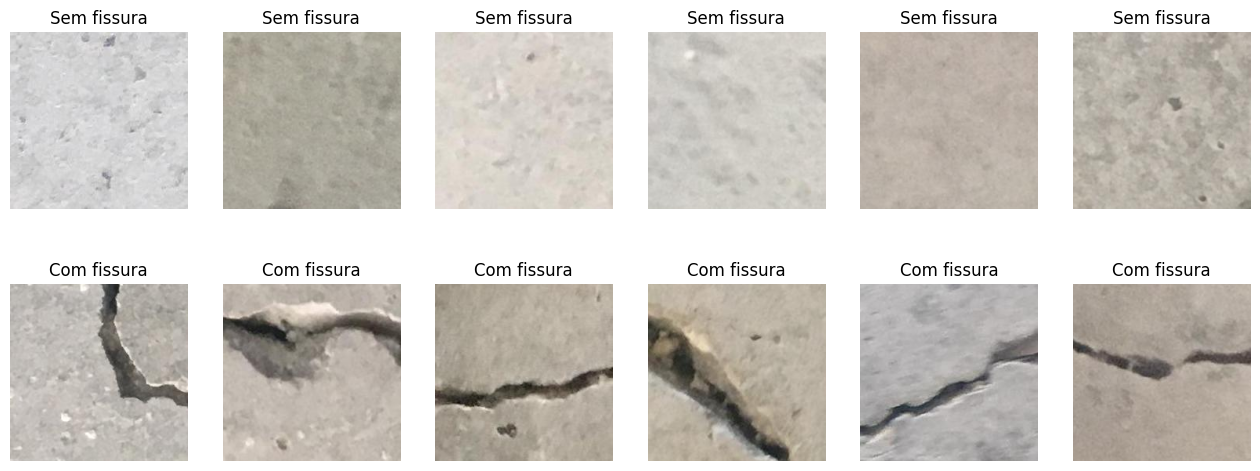

4200 900 900


In [ ]:
import random, matplotlib.pyplot as plt, pandas as pd
from sklearn.model_selection import train_test_split
random.seed(42)

# Etapa 4: examinar as imagens
fig, axs = plt.subplots(2, 6, figsize=(16, 6))
for r, (pasta, nome) in enumerate([(NEG, 'Sem fissura'), (POS, 'Com fissura')]):
    for ax, f in zip(axs[r], random.sample(os.listdir(f'{BASE}/{pasta}'), 6)):
        ax.imshow(Image.open(f'{BASE}/{pasta}/{f}')); ax.set_title(nome); ax.axis('off')
plt.show()

# Etapa 5: amostrar e separar
N = 3000
rows = []
for label, pasta in [(0, NEG), (1, POS)]:
    for f in random.sample(os.listdir(f'{BASE}/{pasta}'), N):
        rows.append((f'{BASE}/{pasta}/{f}', label))

df = pd.DataFrame(rows, columns=['path', 'label'])
train, temp = train_test_split(df, test_size=0.30, stratify=df.label, random_state=42)
val, test   = train_test_split(temp, test_size=0.50, stratify=temp.label, random_state=42)
print(len(train), len(val), len(test))   # esperado: 4200 900 900

# Etapa 6: pré-processamento
IMG, BS = 224, 32

def load(path, label):
    img = tf.io.read_file(path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, (IMG, IMG))
    img = tf.keras.applications.mobilenet_v2.preprocess_input(img)   # normaliza para [-1, 1]
    return img, tf.cast(label, tf.float32)

def make_ds(d, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((d.path.values, d.label.values))
    if shuffle: ds = ds.shuffle(len(d), seed=42)
    return ds.map(load, num_parallel_calls=tf.data.AUTOTUNE).batch(BS).prefetch(tf.data.AUTOTUNE)

train_ds, val_ds, test_ds = make_ds(train, True), make_ds(val), make_ds(test)

In [ ]:
from tensorflow.keras import layers, models

base = tf.keras.applications.MobileNetV2(input_shape=(IMG, IMG, 3), include_top=False, weights='imagenet')
base.trainable = False

model = models.Sequential([base, layers.GlobalAveragePooling2D(), layers.Dropout(0.2),
                           layers.Dense(1, activation='sigmoid')])
model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss='binary_crossentropy', metrics=['accuracy'])

hist = model.fit(train_ds, validation_data=val_ds, epochs=5,
                 callbacks=[tf.keras.callbacks.EarlyStopping(patience=2, restore_best_weights=True)])
model.save('/content/modelo.keras')

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/5
132/132 ━━━━━━━━━━━━━━━━━━━━ 96s 507ms/step - accuracy: 0.9769 - loss: 0.0840 - val_accuracy: 0.9944 - val_loss: 0.0174
Epoch 2/5
132/132 ━━━━━━━━━━━━━━━━━━━━ 6s 48ms/step - accuracy: 0.9967 - loss: 0.0165 - val_accuracy: 0.9933 - val_loss: 0.0126
Epoch 3/5
132/132 ━━━━━━━━━━━━━━━━━━━━ 7s 50ms/step - accuracy: 0.9969 - loss: 0.0112 - val_accuracy: 0.9944 - val_loss: 0.0131
Epoch 4/5
132/132 ━━━━━━━━━━━━━━━━━━━━ 12s 60ms/step - accuracy: 0.9969 - loss: 0.0100 - val_accuracy: 0.9978 - val_loss: 0.0089
Epoch 5/5
132/132 ━━━━━━━━━━━━━━━━━━━━ 6s 44ms/step - accuracy: 0.9981 - loss: 0.0071 - val_accuracy: 0.9956 - val_loss: 0.0094


## Etapa 8: avaliação no conjunto de teste

As métricas do relatório vêm desta célula. O conjunto de teste não foi usado no treino nem na escolha da época.

In [ ]:
import numpy as np
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score, confusion_matrix

LIMIAR = 0.50
y_true = np.concatenate([y.numpy() for _, y in test_ds]).astype(int)
y_prob = model.predict(test_ds, verbose=0).ravel()
y_pred = (y_prob >= LIMIAR).astype(int)

print(f'Imagens de teste: {len(y_true)}')
print(f'Acurácia:  {accuracy_score(y_true, y_pred):.3f}')
print(f'Precisão:  {precision_score(y_true, y_pred):.3f}')
print(f'Recall:    {recall_score(y_true, y_pred):.3f}')
print(f'F1:        {f1_score(y_true, y_pred):.3f}')
tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
print(f'VP={tp}  VN={tn}  FP={fp}  FN={fn}')

In [ ]:
import time

# Latência por imagem (uma imagem por vez, depois de aquecer o modelo)
amostras = test.path.values[:100]
_ = model.predict(load(amostras[0], 0)[0][None, ...], verbose=0)
inicio = time.perf_counter()
for caminho in amostras:
    model.predict(load(caminho, 0)[0][None, ...], verbose=0)
media = (time.perf_counter() - inicio) / len(amostras)
print(f'Latência média: {media*1000:.1f} ms por imagem ({1/media:.0f} imagens por segundo)')